In [1]:
import os
os.environ['PROJ_LIB'] = '/opt/conda/share/proj'

In [2]:
# Import needed packages

import geopandas as gpd
import pandas as pd
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
import seaborn as sns
import contextily as cx
from pysal.viz import mapclassify

from pointpats import distance_statistics
from shapely.geometry import Polygon

In [3]:
# File path to the data
fp_par = '../data/data.parquet'

In [4]:
# Read the data
gdf_par = gpd.read_parquet(fp_par)

# Exploratory Spatial Data Analysis (ESDA)

In [5]:
gdf_par.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 48939 entries, 0 to 48938
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   year       48939 non-null  int16   
 1   cause      48939 non-null  category
 2   areaburnt  48939 non-null  float64 
 3   region     48939 non-null  category
 4   park       2302 non-null   category
 5   ID         48939 non-null  uint64  
 6   geometry   48939 non-null  geometry
dtypes: category(3), float64(1), geometry(1), int16(1), uint64(1)
memory usage: 1.4 MB


In [6]:
# what types of geometries exsit in the data
gdf_par.geom_type.unique()

array(['MultiPolygon', 'Polygon'], dtype=object)

In [7]:
gdf_par.head(5)

,year,cause,areaburnt,region,park,ID,geometry
0,2022,Natural,45023.957801,AB,NaN,7998362902588171649,"MULTIPOLYGON (((-900769.135 1211142.157, -9007..."
1,2022,Natural,737.755249,NT,NaN,9949412462038207732,"MULTIPOLYGON (((-550315.221 1281039.482, -5503..."
2,2022,Natural,9572.430492,NT,NaN,7939118707037355586,"MULTIPOLYGON (((-1340674.355 1709523.598, -134..."
3,2022,Natural,26761.761894,NT,NaN,2011679687128239794,"MULTIPOLYGON (((-869430.587 1333458.376, -8694..."
4,2022,Undetermined,400.728797,YT,NaN,3626459750597420339,"MULTIPOLYGON (((-1792393.251 2222882.973, -179..."


In [8]:
gdf_par['cause'].unique()

['Natural', 'Undetermined', 'Human']
Categories (3, object): ['Human', 'Natural', 'Undetermined']

In [9]:
# the data is projected
gdf_par.crs

<Derived Projected CRS: PROJCRS["Canada_Lambert_Conformal_Conic",BASEGEOGC ...>
Name: Canada_Lambert_Conformal_Conic
Axis Info [cartesian]:
- [east]: Easting (metre)
- [north]: Northing (metre)
Area of Use:
- undefined
Coordinate Operation:
- name: unnamed
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [10]:
# make a copy for further manipulations
data = gdf_par.copy()

In [11]:
data[data['year'] == 2023].info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Int64Index: 2199 entries, 46740 to 48938
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   year       2199 non-null   int16   
 1   cause      2199 non-null   category
 2   areaburnt  2199 non-null   float64 
 3   region     2199 non-null   category
 4   park       83 non-null     category
 5   ID         2199 non-null   uint64  
 6   geometry   2199 non-null   geometry
dtypes: category(3), float64(1), geometry(1), int16(1), uint64(1)
memory usage: 81.5 KB


### Add centroids to data

I decided to use the point pattern analysis methods as the firespots are events, therefore I need to extract an centroid of each polygon and its coordinates

In [12]:
# Extract the centroid of each polygon
data['centroid'] = data['geometry'].centroid

# Extract latitude and longitude from the 'geometry' column
data['latitude'] = data['centroid'].apply(lambda geom: geom.y)
data['longitude'] = data['centroid'].apply(lambda geom: geom.x)

## Check annualy growing trend in the total amount of area burnt (in sqkm)

In [13]:
data['areaburnt_in_sqkm'] = round(data['geometry'].area / 10000, 2)
data['areaburnt_in_sqkm'].head()

0    42642.76
1      696.53
2     9010.43
3    25270.77
4      376.63
Name: areaburnt_in_sqkm, dtype: float64

In [14]:
yearly_area_burnt = data.groupby('year')['areaburnt_in_sqkm'].sum()

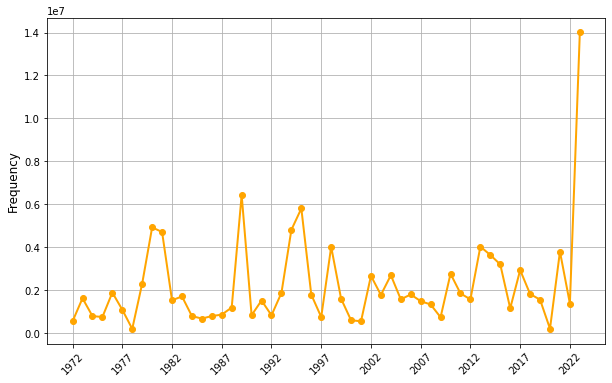

In [15]:
plt.figure(figsize=(10, 6))

plt.plot(yearly_area_burnt.index, yearly_area_burnt.values, marker='o', color='orange', linestyle='-', linewidth=2)

#plt.title('Yearly Amount of Area Burnt (in sqkm)', fontsize=14)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(yearly_area_burnt.index[::5], rotation=45)

plt.grid(True)

plt.savefig('yearly_amount_of_area_burnt(in_sqkm).png', format='png', bbox_inches='tight')

# Step 4: Show the plot
plt.show()

As can be seen from the graph the are ups and donws during the whole period, but the year 2023 is an obvious outlier.

### Inspect locations of 2023 fires compared to locations in all previous years

In [16]:
year_2023 = data[data['year'] == 2023]
years_before_2023 = data[data['year'] < 2023]

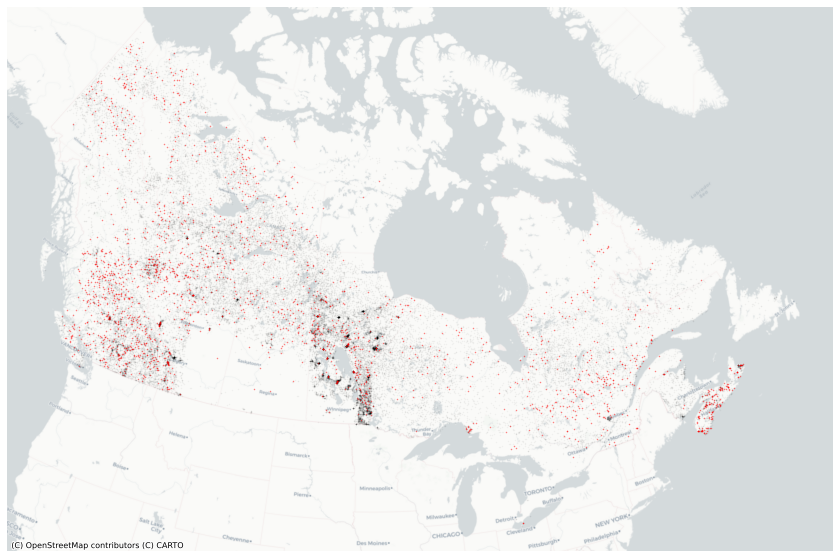

In [17]:
# Plot photographs with smaller, more translucent dots
plt.figure(figsize=(15, 10))


plt.scatter(years_before_2023["longitude"], years_before_2023["latitude"],
    s=0.25,
    c="black",
    alpha=(1/25)
)
plt.scatter(year_2023["longitude"], year_2023["latitude"],
    s=0.25,
    c="red",
    alpha=0.5
)
# remove axis
plt.gca().set_axis_off()
# Add dark basemap
cx.add_basemap(
    plt.gca(), 
    crs=year_2023.crs,
    source=cx.providers.CartoDB.Positron
)

Looking at this, it is hard to suggest that fires in 2023 happened in any distinctly new clusters of locations.

## Segregate the data by decade

We do this because working on the whole dataset at once is resource intensive.

In [18]:
uniform_decades = True
strip_last = False # Strip latest year (2023); no effect if uniform_decades == False
min_year = data['year'].min() + 1
max_year = data['year'].max()
if uniform_decades:
    if strip_last:
        max_year -= 1
    else:
        min_year += 1

decades = []
for year in range(min_year, max_year, 10):
    end_year = min(year + 9, max_year)
    decades.append((year, end_year))
    
    
# Create a function to assign the correct decade label to each row
def assign_decade(year):
    for start, end in decades:
        if start <= year and year <= end:
            return f'{start}-{end}'

# Apply the function to create a new 'decade' column
data['decade'] = data['year'].apply(assign_decade)


Prettify list of decades

In [19]:
decades = sorted(list(data['decade'].dropna().unique()))
decades

['1974-1983', '1984-1993', '1994-2003', '2004-2013', '2014-2023']

In [20]:
data.head()

,year,cause,areaburnt,region,park,ID,geometry,centroid,latitude,longitude,areaburnt_in_sqkm,decade
0,2022,Natural,45023.957801,AB,NaN,7998362902588171649,"MULTIPOLYGON (((-900769.135 1211142.157, -9007...",POINT (-886174.707 1217658.113),1.217658e+06,-8.861747e+05,42642.76,2014-2023
1,2022,Natural,737.755249,NT,NaN,9949412462038207732,"MULTIPOLYGON (((-550315.221 1281039.482, -5503...",POINT (-550635.112 1282875.542),1.282876e+06,-5.506351e+05,696.53,2014-2023
2,2022,Natural,9572.430492,NT,NaN,7939118707037355586,"MULTIPOLYGON (((-1340674.355 1709523.598, -134...",POINT (-1349320.451 1713064.640),1.713065e+06,-1.349320e+06,9010.43,2014-2023
3,2022,Natural,26761.761894,NT,NaN,2011679687128239794,"MULTIPOLYGON (((-869430.587 1333458.376, -8694...",POINT (-870118.517 1341958.224),1.341958e+06,-8.701185e+05,25270.77,2014-2023
4,2022,Undetermined,400.728797,YT,NaN,3626459750597420339,"MULTIPOLYGON (((-1792393.251 2222882.973, -179...",POINT (-1793854.832 2224316.866),2.224317e+06,-1.793855e+06,376.63,2014-2023


## Plot a histogram with areaburnt for each decade in order to detect growing trend

In [21]:
areaburnt_hist = data.groupby('decade')['areaburnt_in_sqkm'].sum()
print(areaburnt_hist)

decade
1974-1983    19961309.28
1984-1993    15871017.42
1994-2003    24426613.13
2004-2013    19905084.96
2014-2023    33750417.91
Name: areaburnt_in_sqkm, dtype: float64


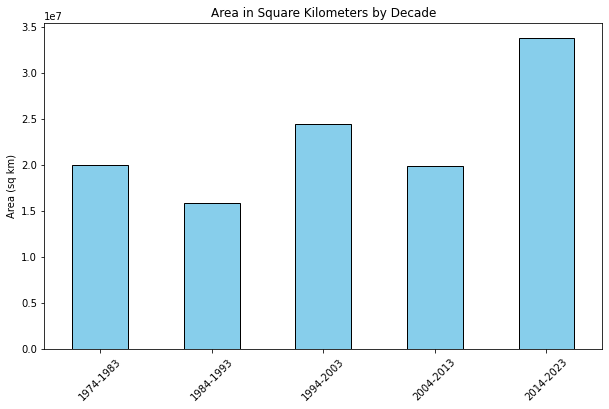

In [22]:
# Create a figure with a specific size (width, height)
plt.figure(figsize=(10, 6))  # Size is in inches (width, height)


# Plotting a bar plot with each decade as a separate bin
areaburnt_hist.plot(kind='bar', color='skyblue', edgecolor='black')

# Adding title and labels
plt.title('Area in Square Kilometers by Decade')
plt.xlabel('')  # Hide the x-axis label
plt.ylabel('Area (sq km)')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=45)

# Show the plot
plt.show()

In [23]:
areburnt_by_decade = data.groupby('decade')['areaburnt'].sum() #in hectares
print(areburnt_by_decade)

decade
1974-1983    2.038866e+07
1984-1993    1.633729e+07
1994-2003    2.489805e+07
2004-2013    2.065587e+07
2014-2023    3.512889e+07
Name: areaburnt, dtype: float64


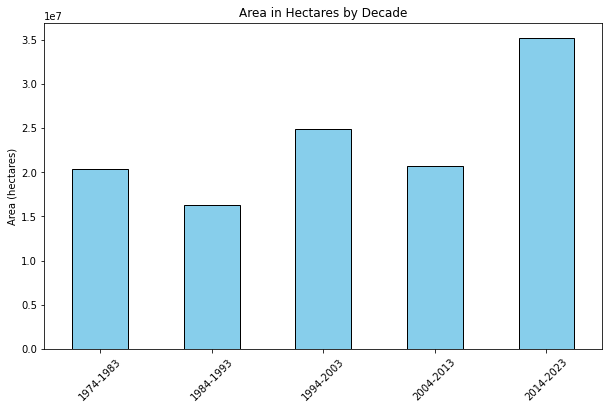

In [24]:
# Create a figure with a specific size (width, height)
plt.figure(figsize=(10, 6))  # Size is in inches (width, height)


# Plotting a bar plot with each decade as a separate bin
areburnt_by_decade.plot(kind='bar', color='skyblue', edgecolor='black')

# Adding title and labels
plt.title('Area in Hectares by Decade')
plt.xlabel('')  # Hide the x-axis label
plt.ylabel('Area (hectares)')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=45)

# Show the plot
plt.show()

### Distribution of the causes

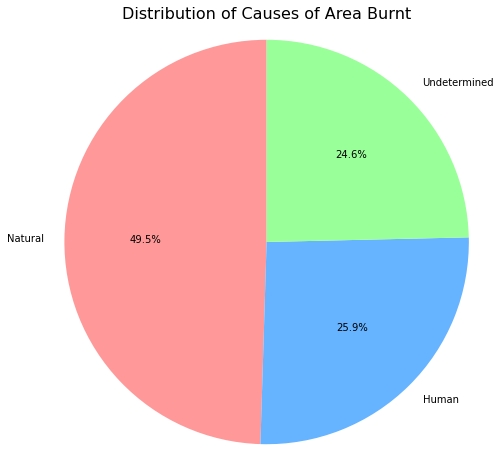

In [25]:

# Count the frequency of each unique cause
cause_counts = data['cause'].value_counts()

# Plot a pie chart
plt.figure(figsize=(8, 8))

# Pie plot for the 'cause' column
plt.pie(cause_counts, labels=cause_counts.index, autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff','#99ff99'])

# Equal aspect ratio ensures the pie chart is circular.
plt.title('Distribution of Causes of Area Burnt', fontsize=16)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

plt.savefig('distribution_of_causes_of_area_burnt.png', format='png', bbox_inches='tight')

# Show the plot
plt.show()

Actually segregate the data by decades. We will work with data by decades, since working on the whole data is too resource intensive. We will mainly use decade 5 below, for no particular reason.

In [26]:
decade_1 = data[data['decade'] == decades[0]]
decade_2 = data[data['decade'] == decades[1]]
decade_3 = data[data['decade'] == decades[2]]
decade_4 = data[data['decade'] == decades[3]]
decade_5 = data[data['decade'] == decades[4]]

In [27]:
def causes(data, label):
    # Count the frequency of each unique cause
    cause_counts = data['cause'].value_counts()

    # Plot a pie chart
    plt.figure(figsize=(8, 8))

    # Pie plot for the 'cause' column
    plt.pie(cause_counts, labels=cause_counts.index, autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff','#99ff99'])

    # Equal aspect ratio ensures the pie chart is circular.
    plt.title('Distribution of Causes of Wildfires in ' + label, fontsize=16)
    plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

    # plt.savefig('distribution_of_causes_of_area_burnt.png', format='png', bbox_inches='tight')

    # Show the plot
    plt.show()

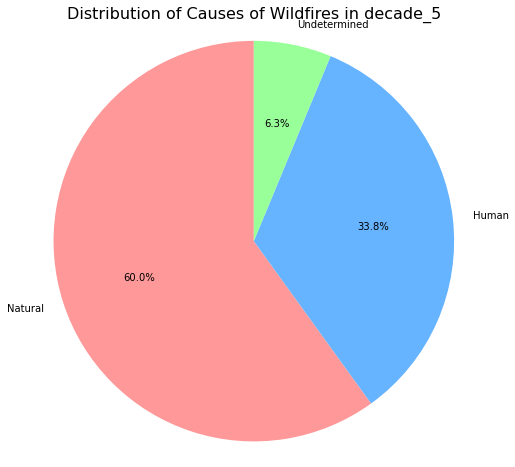

In [28]:
causes(decade_5, 'decade_5')

In [29]:
data.groupby('decade')['cause'].value_counts().unstack().fillna(0)

,Human,Natural,Undetermined
decade,,,
1974-1983,1064,1811,3562
1984-1993,1268,2311,1636
1994-2003,1000,3512,4032
2004-2013,4081,7401,1566
2014-2023,5025,8917,931


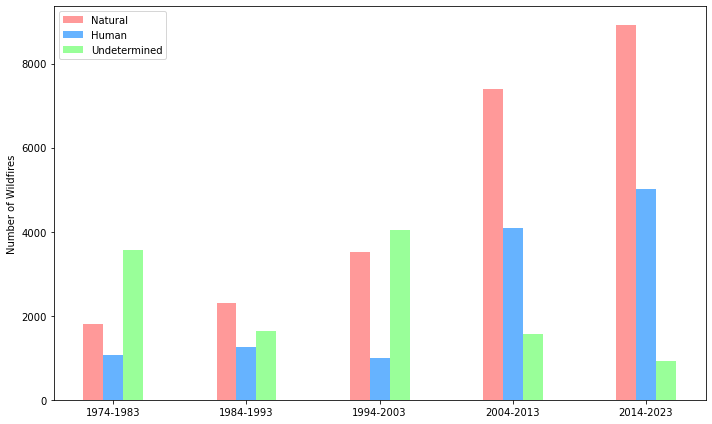

In [30]:
dfs = data.groupby('decade')['cause'].value_counts().unstack().fillna(0)

consistent_order = ['Natural', 'Human', 'Undetermined']
colors = ['#ff9999','#66b3ff','#99ff99']
cause_color_map = {
    'Natural': colors[0],
    'Human': colors[1],
    'Undetermined': colors[2]
}

fig, ax = plt.subplots(figsize=(10, 6))

bar_width = 0.15
index = np.arange(len(dfs))

for i, (decade, row) in enumerate(dfs.iterrows()):
    cause_counts = row[consistent_order].head(3)  # Select the top 3 causes and reindex according to consistent_order
    for j, (cause, count) in enumerate(cause_counts.items()):
        label = cause if i == 0 else ""
        ax.bar(index[i] + j * bar_width, count, bar_width, label=label, color=cause_color_map[cause])

ax.set_ylabel('Number of Wildfires')
ax.set_xticks(index + bar_width)
ax.set_xticklabels(dfs.index)
ax.legend()

plt.tight_layout()
plt.savefig('causes_over_decades.png', format='png', bbox_inches='tight')
plt.show()

## Quantiles choropleth map

In [31]:
quant7 = mapclassify.Quantiles(decade_5["areaburnt_in_sqkm"], k=7)
quant7

Quantiles                     

       Interval          Count
------------------------------
[     0.00,      0.46] |  2129
(     0.46,      1.84] |  2127
(     1.84,      5.63] |  2120
(     5.63,     26.53] |  2123
(    26.53,    146.20] |  2124
(   146.20,   1049.82] |  2125
(  1049.82, 942200.69] |  2125

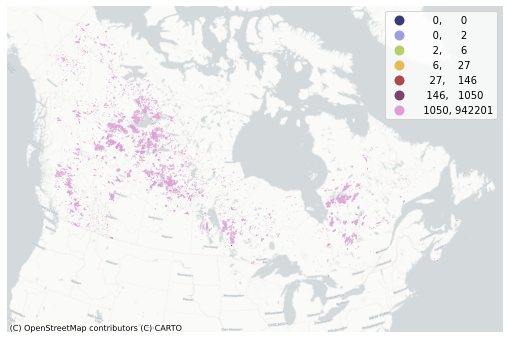

In [32]:

# Set up the figure
f, ax = plt.subplots(1, figsize=(10,6))

decade_5.plot(
    column="areaburnt_in_sqkm", 
    scheme="quantiles", 
    k=7,
    cmap="tab20b",
    legend=True,
    ax=ax,
    legend_kwds={"fmt": "{:.0f}"}
);
# Remove axis frames
ax.set_axis_off()

cx.add_basemap(
    ax, 
    crs=data.crs, 
    source=cx.providers.CartoDB.Positron 
)

plt.savefig('quantile_choropleth_map.png', format='png',  bbox_inches='tight')

Visualize the distribution of areaburnt sizes(in sqkm)

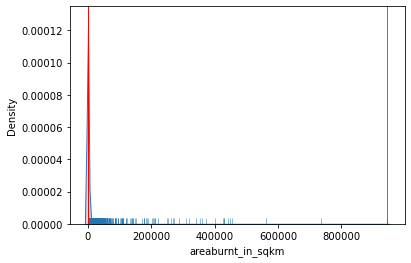

In [33]:
# Set up the figure
f, ax = plt.subplots(1)

# Plot the kernel density estimation (KDE)
sns.kdeplot(decade_5['areaburnt_in_sqkm'], fill=True)

# Add a blue tick for every value at the bottom of the plot (rugs)
sns.rugplot(decade_5['areaburnt_in_sqkm'], alpha=0.5)

#Loop over each break point and plot a vertical red line
for cut in quant7.bins:
    plt.axvline(cut, color='red', linewidth=0.75)
    
# Display image
plt.show()

The data is heavily skewed because of large outliers on the right end. I suspect these polygons are multipolygons, thus covering giant territories.

### Check if the outliers are miltipolygon data types:

In [34]:
mask = decade_5['areaburnt_in_sqkm'] < 100000

outliers = decade_5[~mask]


In [35]:
outliers.geometry.type.unique()

array(['MultiPolygon'], dtype=object)

Indeed, most of outliers have Multipolygon geometry type, but I cannot separate them.

# Run different clustering methods in order to detect fire-prone zones

I decided to use the point pattern analysis methods as the firespots are events, therefore I need to extract an centroid of each polygon and its coordinates

In [36]:
# Extract the centroid of each polygon
data['centroid'] = data['geometry'].centroid

# Extract latitude and longitude from the 'geometry' column
data['latitude'] = data['centroid'].apply(lambda geom: geom.y)
data['longitude'] = data['centroid'].apply(lambda geom: geom.x)

### At first, check if the data is clustered using Ripley's G method:

In [37]:
def Ripleys_G(df, suffix = ''):
    
    coordinates = df[['latitude', 'longitude']]
    g_test = distance_statistics.g_test(
        coordinates, support=40, keep_simulations=True, n_simulations=999
    )


    f,ax = plt.subplots(1,2,figsize=(9,5), 
                        gridspec_kw=dict(width_ratios=(6,3)))
    # plot all the simulations with very fine lines
    ax[0].plot(g_test.support, g_test.simulations.T, color='k', alpha=.01)
    # and show the average of simulations
    ax[0].plot(g_test.support, np.median(g_test.simulations, axis=0), color='cyan', 
             label='median simulation')


    # and the observed pattern's G function
    ax[0].plot(g_test.support, g_test.statistic, label = 'observed', color='red')

    # clean up labels and axes
    ax[0].set_xlabel('distance')
    ax[0].set_ylabel('% of nearest neighbor\ndistances shorter')
    ax[0].legend()
    ax[0].set_xlim(0,60000)
    ax[0].set_title(r"Ripley's $G(d)$ function for decade")

    # plot the pattern itself on the next frame
    ax[1].scatter(coordinates['latitude'], coordinates['longitude'])

    # and clean up labels and axes there, too
    ax[1].set_xticks([])
    ax[1].set_yticks([])
    ax[1].set_xticklabels([])
    ax[1].set_yticklabels([])
    ax[1].set_title('Pattern')
    f.tight_layout()
    
    plt.savefig('ripley_g_analysis' + suffix + '.png', format='png')
    
    plt.show()
    

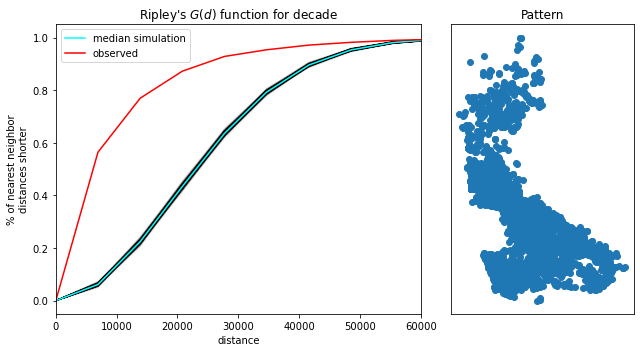

In [38]:
Ripleys_G(decade_1, '_1')

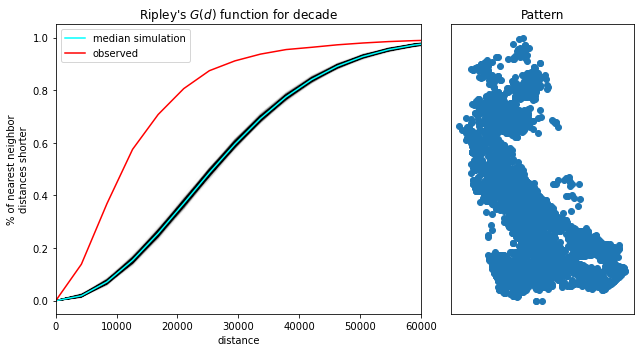

In [39]:
Ripleys_G(decade_2, '_2')

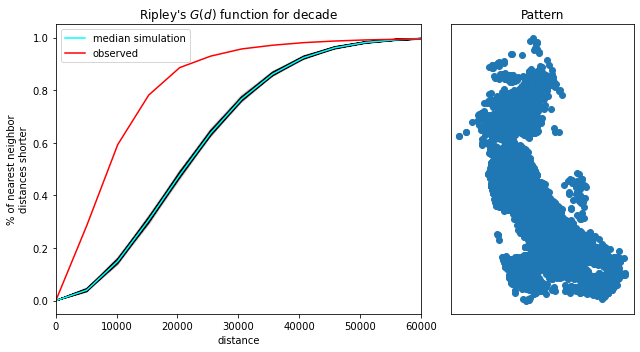

In [40]:
Ripleys_G(decade_3, '_3')

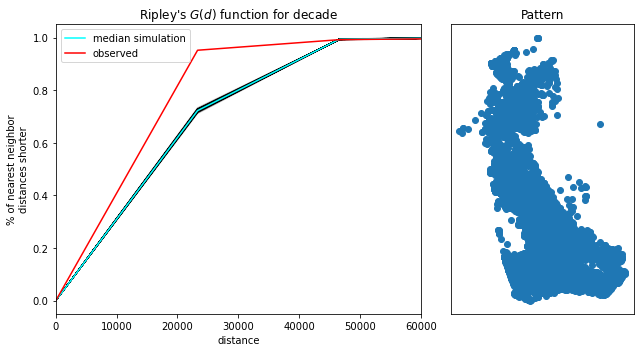

In [41]:
Ripleys_G(decade_4, '_4')

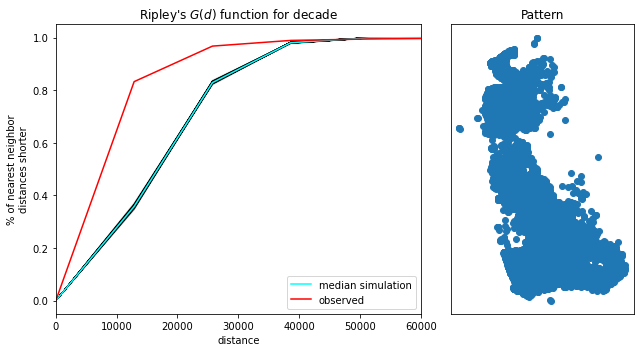

In [42]:
Ripleys_G(decade_5, '_5')

### DBSCAN

To perform DBSCAN, we need to choose eps and min_samples. We guess min_samples=40 to be a good option, and use the Elbow method to find a corresponding eps.

We can perform a Principal Component Analysis to determine the underlying dimensionality of the data set. Doing so requires to make all columns numerical.

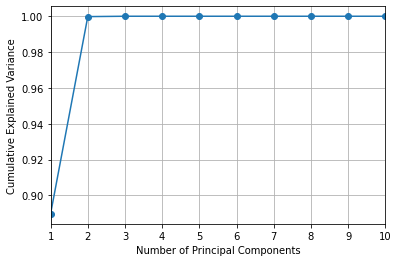

In [62]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder

df = decade_5[['year', 'cause', 'areaburnt', 'region', 'latitude', 'longitude']].copy()
df = pd.get_dummies(df, columns=['cause'])
df = pd.get_dummies(df, columns=['region'])

X = df.values

# Step 1: Apply PCA
pca = PCA()
pca.fit(X)

# Step 2: Plot cumulative explained variance
plt.figure()
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
#plt.title('Explained Variance vs. Components')
plt.xlim(1, 10)
plt.grid(True)
plt.show()

Here, 2 principal components account for over 95% of the variance, and hence, `min_samples=3`, should suffice.

We can now use the Elbow method to estimate a suitable `epsilon`.

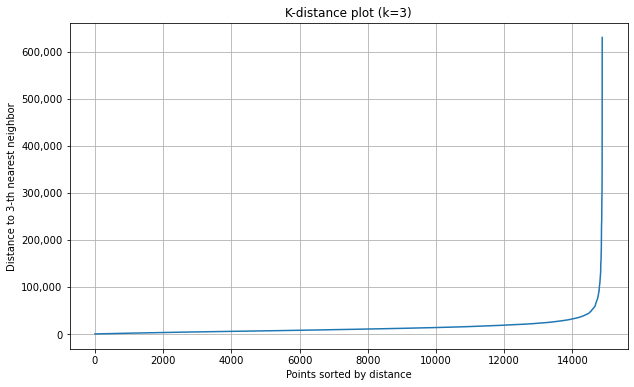

In [53]:
k = 3 # k is typically min_samples - 1
neigh = NearestNeighbors(n_neighbors=k)
neigh.fit(X)
distances, indices = neigh.kneighbors(X)

# Sort the distances to plot the k-distance
distances = np.sort(distances[:, k-1], axis=0)

# Plot the sorted distances (K-distance plot)
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(distances) + 1), distances)
plt.title(f"K-distance plot (k={k})")
plt.xlabel('Points sorted by distance')
plt.ylabel(f'Distance to {k}-th nearest neighbor')

# Format ticks
formatter = ticker.FuncFormatter(lambda x, p: format(int(x), ','))
plt.gca().yaxis.set_major_formatter(formatter)

plt.grid(True)
plt.show()

`50.000` seems likes a good guess for `epsilon`, since this is the elbow of the graph.

In [57]:
X = decade_5[['latitude', 'longitude']]

In [58]:
len(X)

14873

In [59]:
algo.fit(X)

DBSCAN(eps=50000, min_samples=3)

In [60]:
lbls = pd.Series(algo.labels_, index=decade_5.index)
lbls.unique()

array([ 0, -1,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32,
       33, 34, 40, 35, 36, 42, 37, 38, 39, 41])

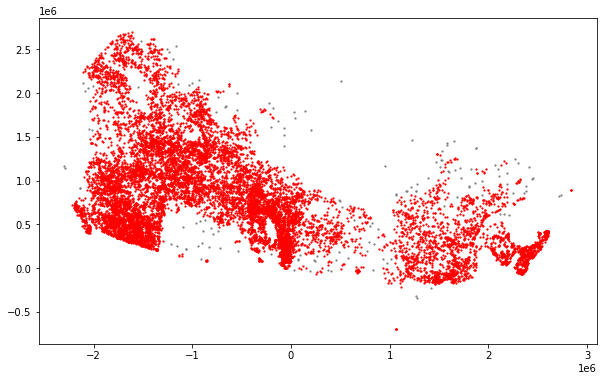

In [61]:
# Setup figure and axis
f, ax = plt.subplots(1, figsize=(10, 6))

# subset points that are not part of any cluster (noise)
noise = decade_5.assign(
    lbls=lbls
).query("lbls == -1")

# Plot noise in grey
ax.scatter(
    noise["longitude"], 
    noise["latitude"], 
    c='grey', 
    s=5, 
    linewidth=0
)
# Plot all points that are not noise in red
ax.scatter(
    decade_5.loc[decade_5.index.difference(noise.index), "longitude"], 
    decade_5.loc[decade_5.index.difference(noise.index), "latitude"],
    c="red",
    s=5,
    linewidth=0
)

plt.savefig("dbscan.png", format="png", bbox_inches='tight') 

# Display the figure
plt.show()

In [40]:
# Print only the first five values
algo.core_sample_indices_[:5]

array([388, 451, 603, 708, 827])

### KDE

Let's visualize fire intensity using KDE, which gives us a smooth representation of fire hotspots.

In [177]:
def kde_epicenters(data, depth=8, save=False, suffix='', show=True):
    # Setup figure and axis
    f, ax = plt.subplots(1, figsize=(12, 12))

    longitude = data["longitude"]
    latitude = data["latitude"]

    # Add KDE layer that displays probability surface
    kde = sns.kdeplot(
            longitude, 
            latitude, 
            n_levels=10, 
            shade=True,
            alpha=0.25,
            cmap="viridis"
        )

    # Extract contour levels
    contours = ax.collections[depth]
    # 8 gives smallest area centers with most fires occurring, but then we don't get Nova Scotia.
    # 4 includes Nova Scotia, but gives a rather large area in central Canada.

    # Function to convert contour paths to polygons
    def contour_to_polygons(contour):
        polygons = []
        for pathcollection in contour.get_paths():
            for path in pathcollection.to_polygons():
                polygon = Polygon(path)
                polygons.append(polygon)
        return polygons

    # Convert contours to polygons
    epicenters = contour_to_polygons(contours)
    
    # Remove polygons fully contained in other polygons
    top_level_epicenters = []
    for i, poly in enumerate(epicenters):
        contained = False
        for j, other in enumerate(epicenters):
            if i != j and poly.within(other):
                contained = True
                break
        if not contained:
            top_level_epicenters.append(poly)
    epicenters = top_level_epicenters
    
    # Add basemap 
    cx.add_basemap(
        ax, 
        crs=data.crs,  
        source=cx.providers.CartoDB.Positron 
    )

    # Add title of the map
    ax.set_title("KDE of fires in Canada")

    for polygon in epicenters:
        x, y = polygon.exterior.xy
        plt.plot(x, y, color='red', linewidth=2)

    if save:
        plt.savefig('kde' + suffix + '.png', format="png", bbox_inches='tight')
        
    if show:
        # Draw map
        plt.show()
    
    return epicenters

In [158]:
def epicenter_map(kde_depth=8, suffix='', save=False, show_steps=True):
    
    grouped = data.groupby('decade')
    
    epicenters = []
    for _, group in grouped:
        epicenters.append(kde_epicenters(group, depth=kde_depth, show=show_steps))

    # Create a colormap
    cmap = plt.get_cmap('viridis', len(decades))

    # Create the plot
    fig, ax = plt.subplots(1, figsize=(12, 12))

    # Plot each polygon collection with a color from the colormap
    for i, polygons in enumerate(epicenters):
        color = cmap(i)
        for polygon in polygons:
            mpl_polygon = mpatches.Polygon(polygon.exterior.coords, closed=True)
            ax.add_patch(mpl_polygon)
            mpl_polygon.set_color(color)
            mpl_polygon.set_alpha(0.4)  # Optional: set transparency

    # Set the limits of the plot (adjust as needed)
    ax.set_xlim(-3000000, 3000000)
    ax.set_ylim(-1000000, 3000000)

    # Add basemap
    cx.add_basemap(
        ax, 
        crs=data.crs,  
        source=cx.providers.CartoDB.Positron 
    )

    # Create a legend
    legend_patches = [mpatches.Patch(color=cmap(i), label=decade) for i, (decade, _) in enumerate(grouped)]
    ax.legend(handles=legend_patches, title='Decades')

    if save:
        plt.savefig('KDE for fire-prone zones over decades' + suffix + '.png', format='png', bbox_inches='tight')

    # Show the plot
    plt.show()

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


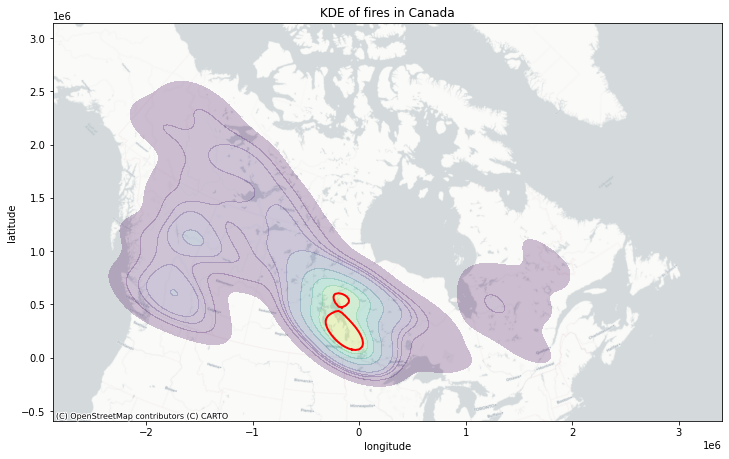

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


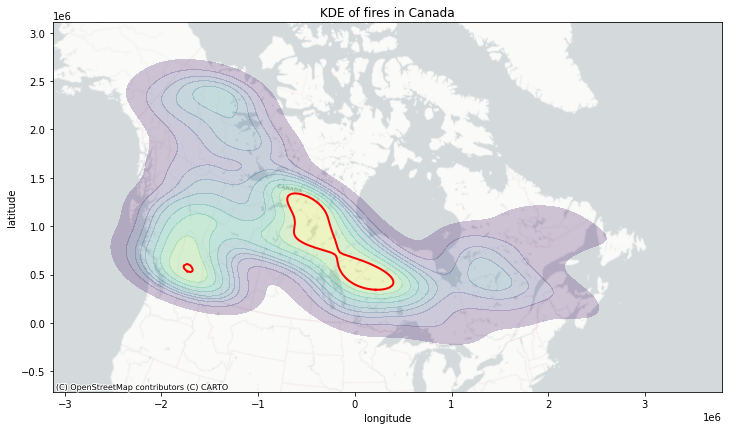

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


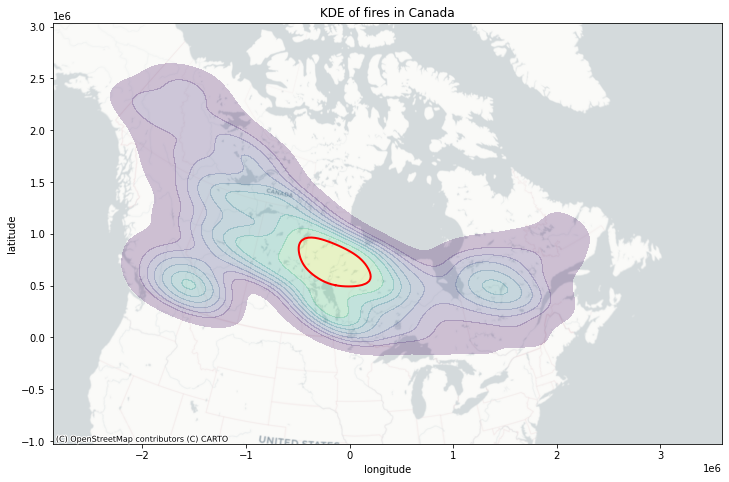

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


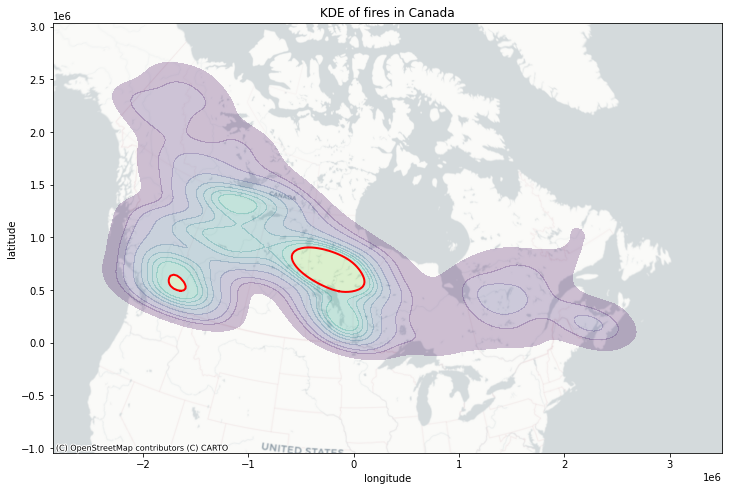

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


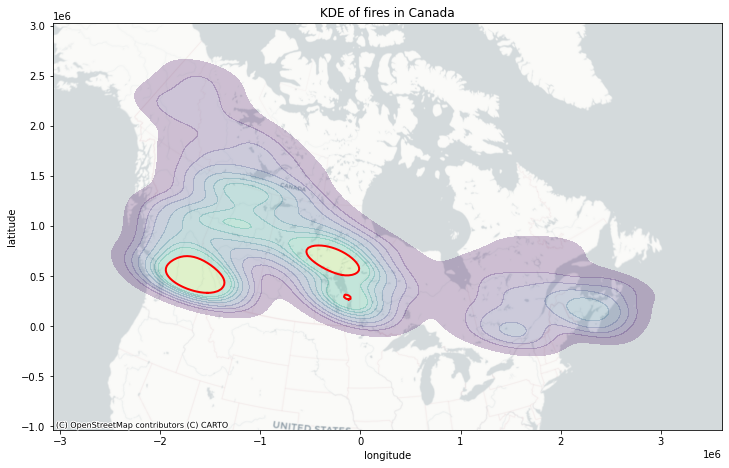

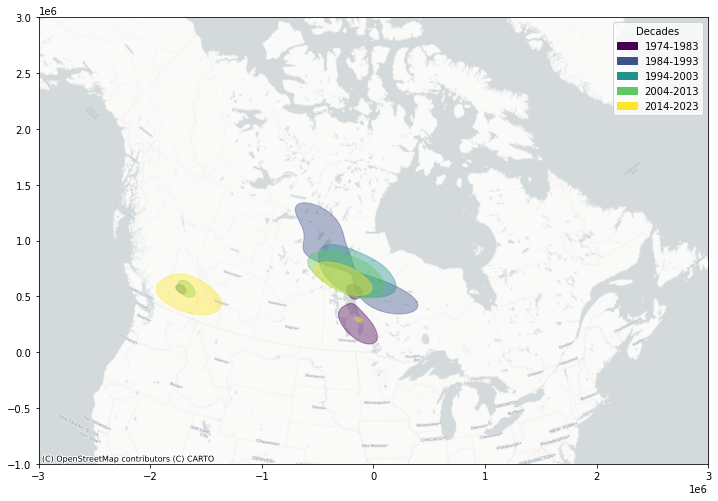

In [153]:
epicenter_map()

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(
/opt/conda/lib/python3.9/site-packages/seab

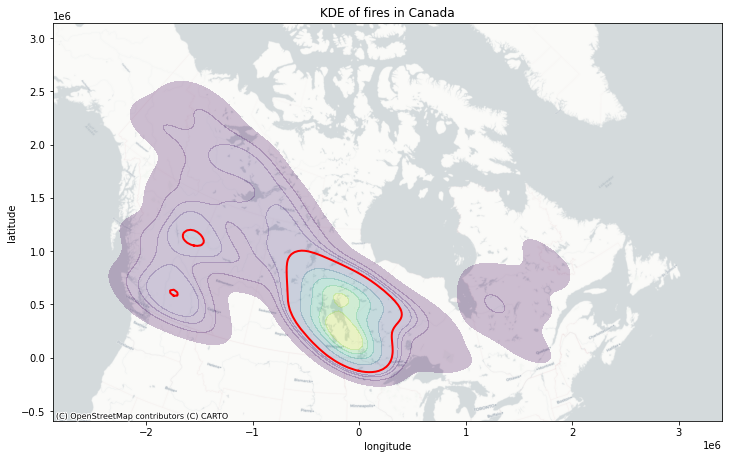

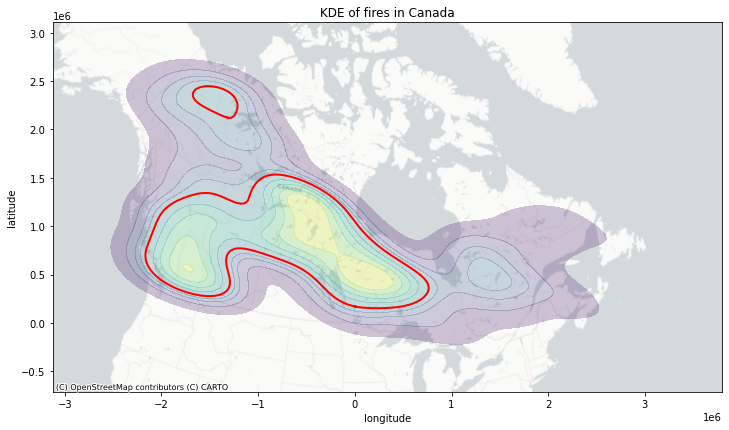

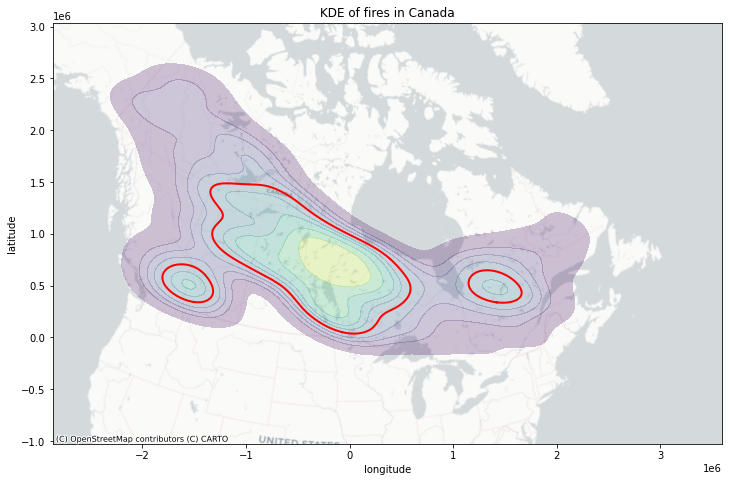

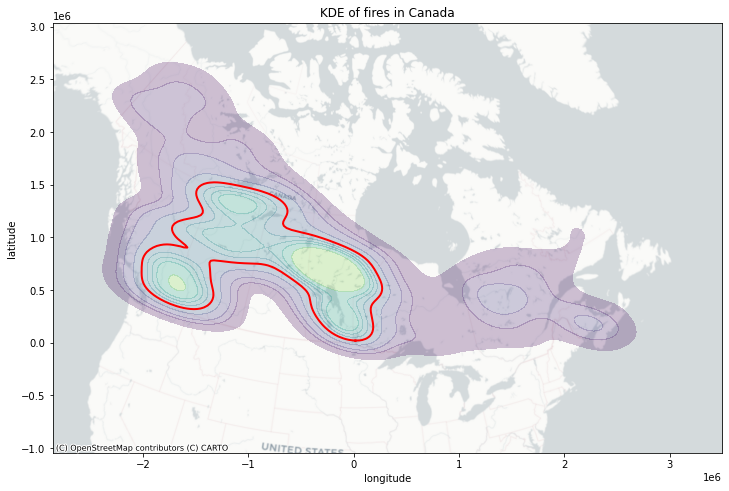

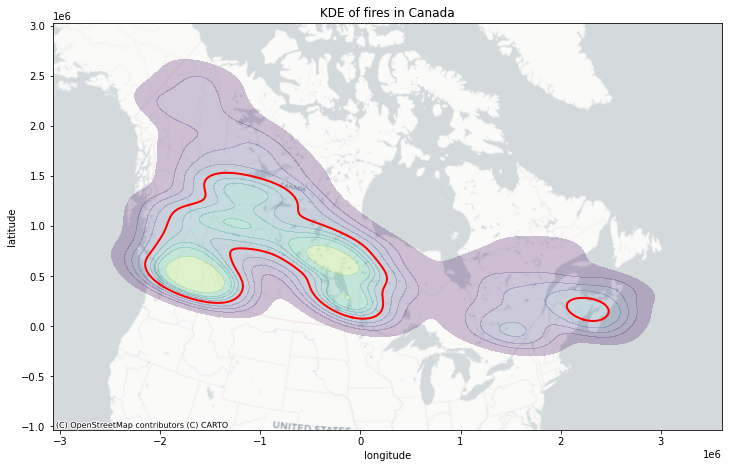

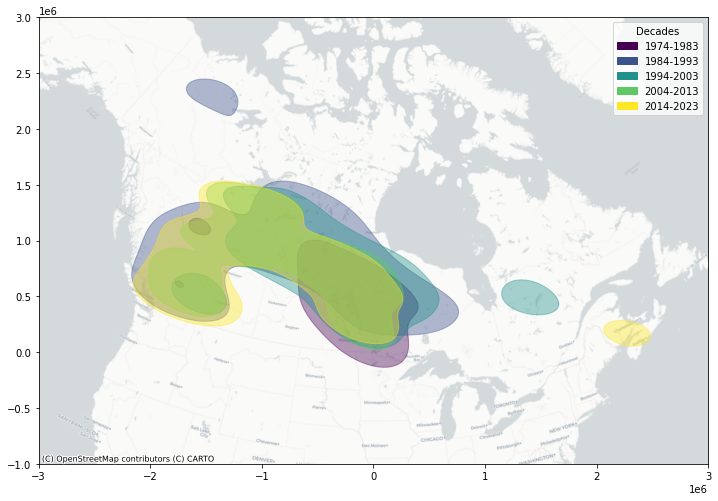

In [178]:
epicenter_map(kde_depth=4, show_steps=False, save=True, suffix=' wide')

**Observations:**

1. Historically, most wildfires occur in the center of Canada.
2. For the past 3 decades there has been a growing tendency for wildfires to also occur in South-West Canada.

/opt/conda/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


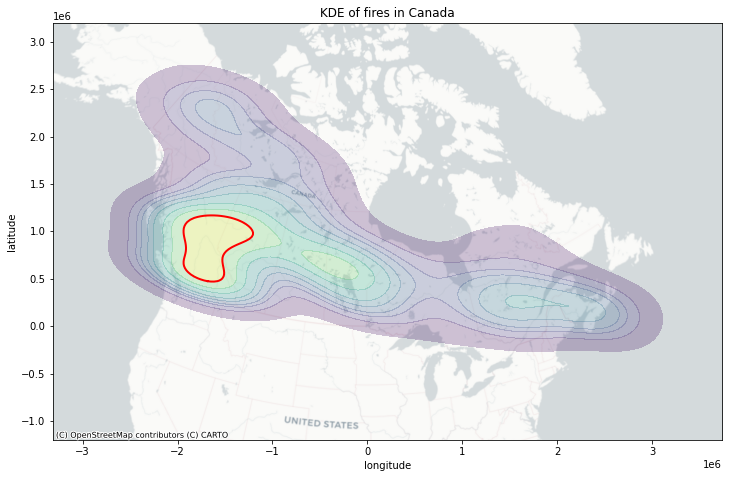

In [59]:
epicenters_2023 = kde_epicenters(year_2023)